In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error,r2_score
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

In [7]:
df=pd.read_csv('fare_processes_data.csv')

In [6]:
df

,Unnamed: 0,trip_duration,distance_traveled,num_of_passengers,fare,surge_applied
0,0,748,2.75,1,75.00,0
1,1,1187,3.43,1,105.00,0
2,2,730,3.12,1,71.25,1
3,3,671,5.63,3,90.00,0
4,4,329,2.09,1,45.00,0
...,...,...,...,...,...,...
182704,209667,354,1.24,1,45.00,0
182705,209668,1617,8.42,1,150.00,0
182706,209669,438,1.29,1,48.75,1
182707,209670,571,2.82,1,63.75,0


In [8]:
# train test
x=df.drop(['Unnamed: 0', 'fare'],axis=1) #Unnamed - old index, fare- dependent variable shouldn't be there
y=df['fare'] # dependent variable only

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.20, random_state=12) #random_state - logisctic 


In [9]:
xtrain.shape, ytrain.shape # check both should be equal and start to build the model

((146167, 4), (146167,))

In [10]:
xtest.shape,ytest.shape

((36542, 4), (36542,))

In [11]:
# linearity
from scipy.stats import pearsonr
for i in x.columns:
    print(f"for {i} ---> {pearsonr(df[i],df['fare'])[0]}")

for trip_duration ---> 0.6396216962215
for distance_traveled ---> 0.6595935540941464
for num_of_passengers ---> 0.009774376044870994
for surge_applied ---> 0.22312267760387366


In [12]:
 # or use df.corr()-->to find pearsonr
df.corr()

,Unnamed: 0,trip_duration,distance_traveled,num_of_passengers,fare,surge_applied
Unnamed: 0,1.000000,0.002307,0.001296,0.002671,0.003286,0.000381
trip_duration,0.002307,1.000000,0.763590,0.005553,0.639622,0.313199
distance_traveled,0.001296,0.763590,1.000000,0.007433,0.659594,0.330076
num_of_passengers,0.002671,0.005553,0.007433,1.000000,0.009774,0.006479
fare,0.003286,0.639622,0.659594,0.009774,1.000000,0.223123
surge_applied,0.000381,0.313199,0.330076,0.006479,0.223123,1.000000


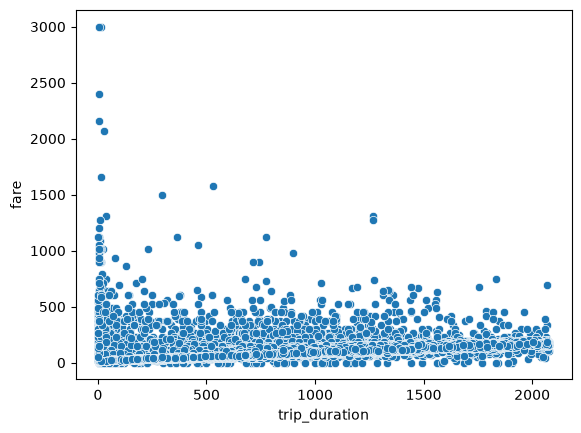

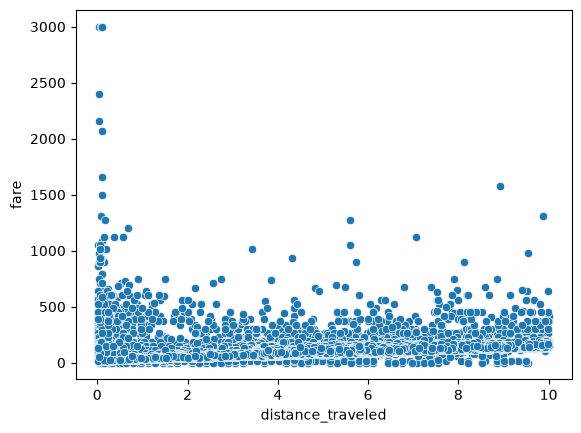

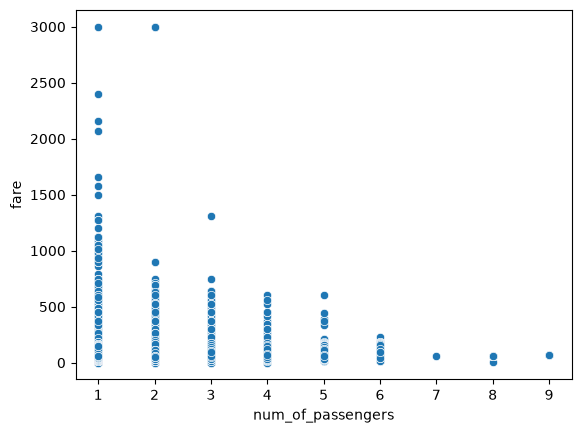

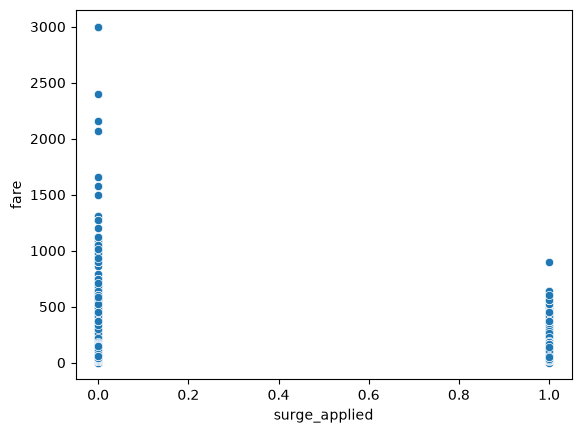

In [13]:
# visualizeed way

for i in x.columns:
    sns.scatterplot(x=df[i],y=df['fare'])
    plt.show()

In [14]:
# model building

model=LinearRegression()
model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.04, 8.83, 0.22,-1.66]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['trip_duration','distance_traveled','num_of_passengers','surge_applied']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.57
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [15]:
model.intercept_

np.float64(22.574643150548553)

In [16]:
model.coef_

array([ 0.03753593,  8.82940749,  0.21870401, -1.6561368 ])

In [21]:
xtest

,trip_duration,distance_traveled,num_of_passengers,surge_applied
50981,649,3.09,5,0
72427,147,0.37,1,0
57792,786,2.56,1,0
127448,1240,5.78,1,1
92525,509,2.67,2,1
...,...,...,...,...
36302,581,1.83,1,1
137408,1346,5.63,1,1
114462,1435,5.81,1,0
147081,157,0.50,1,1


In [22]:
ytest

50981      71.25
72427      26.25
57792      75.00
127448    116.25
92525      60.00
           ...  
36302      56.25
137408    123.75
114462    127.50
147081     26.25
91350      93.75
Name: fare, Length: 36542, dtype: float64

In [17]:
predicted=model.predict(xtest)
predicted

array([ 75.31185113,  31.57800969,  74.89987159, ..., 127.95626472,
        31.44505517,  97.02916632], shape=(36542,))

In [18]:
result_df=pd.DataFrame()
result_df['actual']=ytest
result_df['predicted']=predicted

In [19]:
result_df

,actual,predicted
50981,71.25,75.311851
72427,26.25,31.578010
57792,75.00,74.899872
127448,116.25,118.715739
92525,60.00,64.036221
...,...,...
36302,56.25,59.103402
137408,123.75,121.370137
114462,127.50,127.956265
147081,26.25,31.445055


In [20]:
r2_score(ytest,predicted)

0.5350635682836113

In [21]:
# build model using stats.api
# multicollinearity
sm_model=sm.OLS(ytrain,xtrain).fit()
sm_model

In [22]:
sm_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                   fare   R-squared (uncentered):                   0.855
Model:                            OLS   Adj. R-squared (uncentered):              0.855
Method:                 Least Squares   F-statistic:                          2.160e+05
Date:                Thu, 22 Oct 2026   Prob (F-statistic):                        0.00
Time:                        20:47:23   Log-Likelihood:                     -7.2596e+05
No. Observations:              146167   AIC:                                  1.452e+06
Df Residuals:                  146163   BIC:                                  1.452e+06
Df Model:                           4                                                  
Covariance Type:            nonrobust                                                  
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
trip_duration         0.0502      0.000    150.472      0.000       0.050       0.051
distance_traveled     9.7473      0.066    147.621      0.000       9.618       9.877
num_of_passengers     5.5821      0.081     68.753      0.000       5.423       5.741
surge_applied        -1.8584      0.221     -8.428      0.000      -2.291      -1.426
==============================================================================
Omnibus:                   380419.625   Durbin-Watson:                   1.977
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      18754598878.516
Skew:                          29.984   Prob(JB):                         0.00
Kurtosis:                    1756.804   Cond. No.                     1.97e+03
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 1.97e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

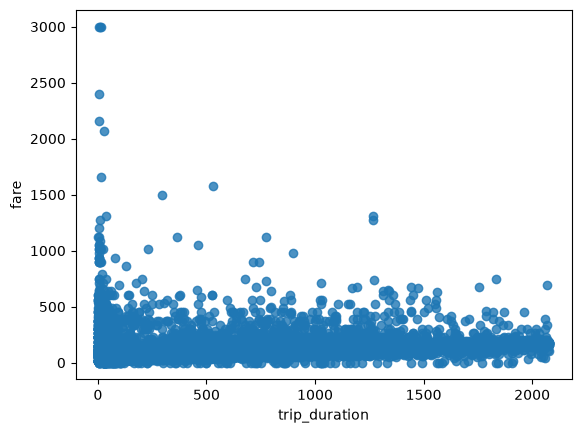

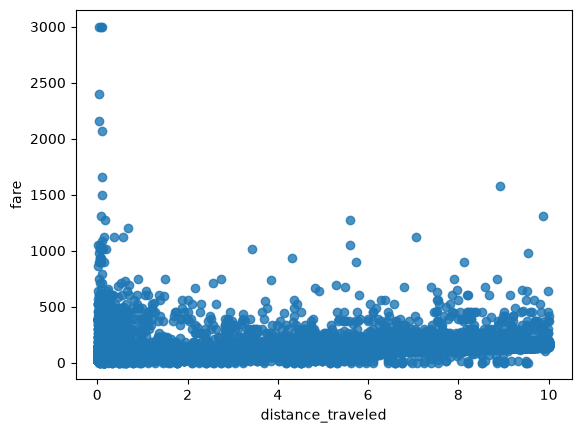

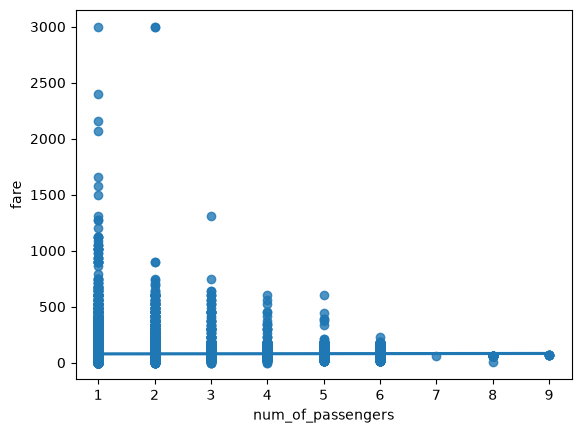

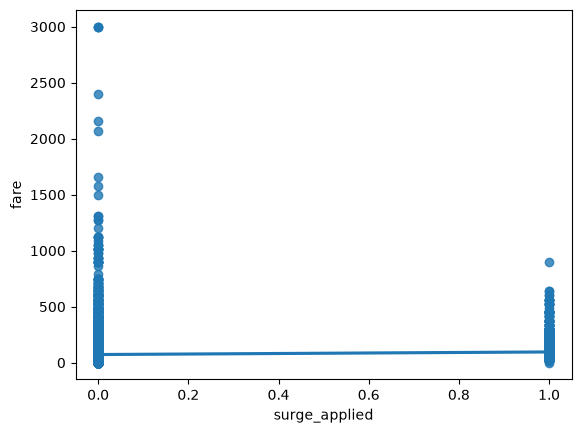

In [28]:
# Regplot -Linearity
for i in x.columns:
    sns.regplot(x=df[i],y=df['fare'])
    plt.show()

<Axes: xlabel='fare', ylabel='Density'>

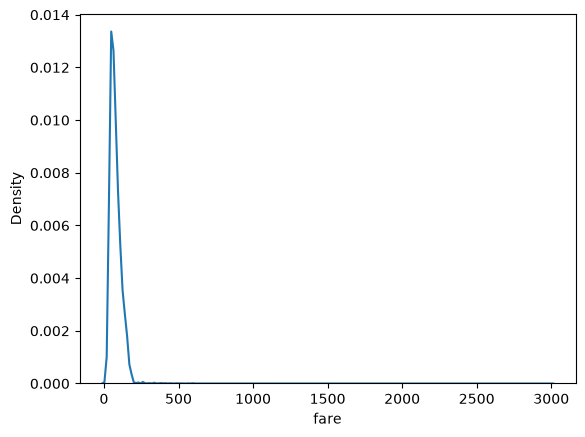

In [33]:
#Normality
sns.kdeplot(df['fare'])


C:\Users\hp\AppData\Local\Temp\ipykernel_28384\1195996103.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['fare'])


<Axes: xlabel='fare', ylabel='Density'>

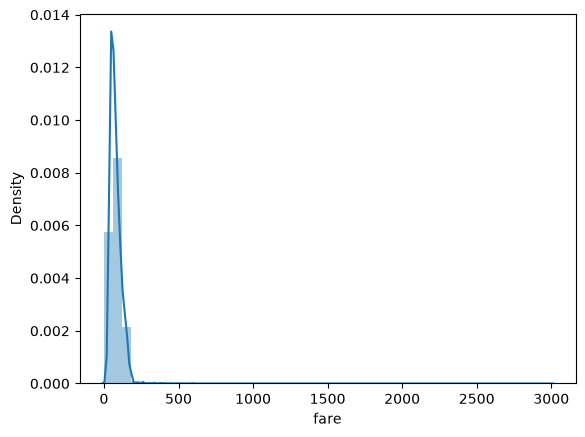

In [34]:
sns.distplot(df['fare'])

In [36]:
df.shape

(182709, 6)

In [37]:
from scipy.stats import anderson
anderson(df['fare'])

C:\Users\hp\AppData\Local\Temp\ipykernel_28384\3083538280.py:2: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  anderson(df['fare'])


AndersonResult(statistic=np.float64(5616.639581033087), critical_values=array([0.561, 0.631, 0.752, 0.873, 1.035]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(78.87811396811323), scale=np.float64(45.389220627353104))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')

In [42]:
# homoscedasity
from statsmodels.stats.diagnostic import het_breuschpagan
xtrains = sm.add_constant(xtrain)
model = sm.OLS(ytrain, xtrains).fit()

# Breusch-Pagan test
het_breuschpagan(model.resid, model.model.exog)

# conclusion reject h0

(np.float64(102.16146403456379),
 np.float64(3.4087647730374265e-21),
 np.float64(25.557355308586782),
 np.float64(3.354172092679296e-21))